# What informs our Photo-z Model?

In [1]:
import copy
import itertools
from math import factorial
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

torch.set_default_dtype(torch.float64)
%matplotlib inline
rng = np.random.default_rng(0)

## get the data and fit an MLP
Same data as Lecture 12:  26,700 SDSS galaxies, inputs $u-g$, $g-r$, $r-i$, $i-z$ and $r$, the same 80/10/10 split. (If the cache is missing, run the Lecture 12 notebook first.)

In [2]:
data = np.load('/home/asamcnaughton/gitrepos/ast384c/inclass/lec12_nn/data/sdss_photoz.npz')
mag, zspec, zerr = data['mag'].astype(float), data['z'].astype(float), data['z_err'].astype(float)
X = np.column_stack([mag[:, :-1] - mag[:, 1:], mag[:, 2]])
names = ['u-g', 'g-r', 'r-i', 'i-z', 'r']
n, p = X.shape
perm = np.random.default_rng(12).permutation(n)
i_tr, i_va, i_te = perm[:int(0.8 * n)], perm[int(0.8 * n):int(0.9 * n)], perm[int(0.9 * n):]
z_te = zspec[i_te]

def nmad(zphot, ztrue):
    dz = (zphot - ztrue) / (1 + ztrue)
    return 1.4826 * np.median(np.abs(dz - np.median(dz)))

print(f'{n} galaxies, {p} features; train {len(i_tr)}, validation {len(i_va)}, test {len(i_te)}')

26700 galaxies, 5 features; train 21360, validation 2670, test 2670


Now train an MLP with standardized/whitened inputs, three hidden layers of 64, MSE loss, Adam and early stopping. Use `nmad` to score the MLP. 

In [3]:
z_mu, z_sd = zspec[i_tr].mean(), zspec[i_tr].std()

def fit_mlp(Xf, seed=0):
    ''' Train an MLP on columns Xf and return a function that predicts f(X) = z
    '''
    mu, sd = Xf[i_tr].mean(0), Xf[i_tr].std(0)
    Xs, ys = torch.tensor((Xf - mu) / sd), torch.tensor((zspec - z_mu) / z_sd)
    torch.manual_seed(seed)

    net = nn.Sequential(
        nn.Linear(Xf.shape[1], 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, 1))
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    loader = DataLoader(TensorDataset(Xs[i_tr], ys[i_tr]), batch_size=256, shuffle=True,
                        generator=torch.Generator().manual_seed(seed + 1))
    best = np.inf
    for epoch in range(300):
        for xb, yb in loader:
            loss = F.mse_loss(net(xb)[:, 0], yb)
            opt.zero_grad()
            loss.backward()
            opt.step()

        with torch.no_grad():
            val = F.mse_loss(net(Xs[i_va])[:, 0], ys[i_va]).item()

        if val < best:
            best, best_state, best_epoch = val, copy.deepcopy(net.state_dict()), epoch

        elif epoch - best_epoch >= 10:
            break

    net.load_state_dict(best_state)
    f = lambda A: net(torch.tensor((A - mu) / sd))[:, 0].detach().numpy() * z_sd + z_mu
    f.net, f.mu, f.sd = net, mu, sd
    return f

f_mlp = fit_mlp(X)

## permutation importance and LOFO

**Permutation importance:** shuffle one column of the *test* set and measure how much worse the model gets. 
Report the ratio of test MSE after/before.

**Leave one feature out (LOFO):** retrain the model without feature $j$ and compare test MSE. 

In [4]:
print(f'test mse = {nmad(f_mlp(X[i_te]), z_te):.4f}')

mse = lambda zp: np.mean((zp - z_te)**2)
mse0 = mse(f_mlp(X[i_te]))

for j, name in enumerate(names):
    ratios = []
    for _ in range(1):                       
        Xp = X[i_te].copy()
        Xp[:, j] = rng.permutation(Xp[:, j])
        ratios.append(mse(f_mlp(Xp)) / mse0)
    print(f'{name:>4}: MSE ratio = {np.mean(ratios):.2f}')

test mse = 0.0152
 u-g: MSE ratio = 3.17
 g-r: MSE ratio = 14.26
 r-i: MSE ratio = 1.77
 i-z: MSE ratio = 1.25
   r: MSE ratio = 2.15


In [5]:
lofo = {}
for j, name in enumerate(names):
    Xj = np.delete(X, j, axis=1)               
    f_j = fit_mlp(Xj)                          
    lofo[name] = mse(f_j(Xj[i_te])) / mse0
    print(f'without {name:>4}: MSE ratio = {lofo[name]:.2f}')

without  u-g: MSE ratio = 1.56
without  g-r: MSE ratio = 1.71
without  r-i: MSE ratio = 1.13
without  i-z: MSE ratio = 1.03
without    r: MSE ratio = 1.19


## Shapley values
Shapley values come from cooperative game theory: the features are players who together produce the prediction, and we split the "payout" fairly among them. 
The value of a coalition $S$ of features is the average prediction when the features in $S$ are fixed to this galaxy's values and
the rest are drawn from the data:

$$v(S) = \mathbb E_{X_{\bar S}}\big[f(x_S, X_{\bar S})\big].$$

Feature $j$'s Shapley value is its marginal contribution $v(S\cup\{j\})-v(S)$, averaged over all orders
in which the features could join:

$$\phi_j = \sum_{S\subseteq P\setminus\{j\}} \frac{|S|!\,(p-|S|-1)!}{p!}\,\big[v(S\cup\{j\})-v(S)\big].$$

With $p = 5$ features there are only $2^5 = 32$ coalitions, so we can compute this exactly. Use the `shapley` function below to calculate the shapley values for each feature and discuss its contributions.

In [6]:
def shapley(f, xs, background):
    ''' Exact Shapley values of f at each row of xs; absent features drawn from background.
    '''
    m, B, p = len(xs), len(background), xs.shape[1]
    coalitions = list(itertools.product([0, 1], repeat=p))
    v = {}
    for S in coalitions:
        mask = np.array(S, bool)
        Z = np.repeat(background[None], m, 0)               # m x B x p
        Z[:, :, mask] = xs[:, None, mask]                   # features in S take the galaxy's values
        v[S] = f(Z.reshape(-1, p)).reshape(m, B).mean(1)
    phi = np.zeros((m, p))
    for j in range(p):
        for S in coalitions:
            if S[j]:
                continue
            s = sum(S)
            weight = factorial(s) * factorial(p - s - 1) / factorial(p)
            with_j = list(S); with_j[j] = 1
            phi[:, j] += weight * (v[tuple(with_j)] - v[S])
    return phi, v[(0,) * p]


i0 = i_te[np.argsort(z_te)[2500]] # a galaxy at z = 0.33
x0 = X[i0]
background = X[i_tr][rng.choice(len(i_tr), 100, replace=False)]


phi0, base0 = shapley(f_mlp, x0[None], background)
print(f'galaxy {i0}: f(x) = {f_mlp(x0[None])[0]:.4f},  E[f] = v(empty) = {base0[0]:.4f}')
print('   ' + '  '.join(f'phi[{s}] = {v:+.4f}' for s, v in zip(names, phi0[0])))
print(f'   sum of phi = {phi0.sum():+.4f}  vs  f(x) - E[f] = {f_mlp(x0[None])[0] - base0[0]:+.4f}')

galaxy 15142: f(x) = 0.3136,  E[f] = v(empty) = 0.1198
   phi[u-g] = +0.0053  phi[g-r] = +0.1483  phi[r-i] = +0.0146  phi[i-z] = +0.0011  phi[r] = +0.0246
   sum of phi = +0.1938  vs  f(x) - E[f] = +0.1938


Now apply `shapley` to 1000 test galaxies and calculate shapley importance (absolute Shapley value averaged over multiple galaxies). Make a nice Shapley importance bar plot.

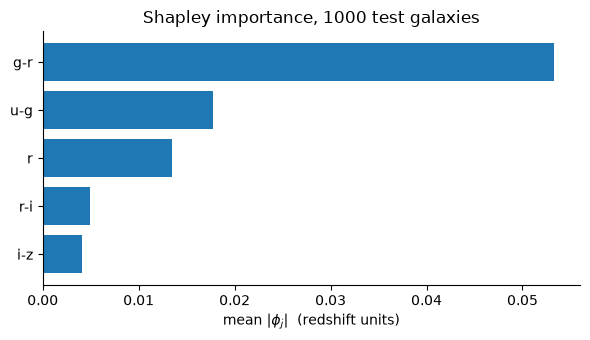

 u-g: 0.0178
 g-r: 0.0533
 r-i: 0.0049
 i-z: 0.0041
   r: 0.0135


In [7]:
idx = rng.choice(i_te, 1000, replace=False)
phi, base = shapley(f_mlp, X[idx], background)       

importance = np.abs(phi).mean(0)
order = np.argsort(importance)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(np.array(names)[order], importance[order], color='C0')
ax.set_xlabel(r'mean $|\phi_j|$  (redshift units)')
ax.set_title('Shapley importance, 1000 test galaxies')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

for s, v in zip(names, importance):
    print(f'{s:>4}: {v:.4f}')

# Where is the CNN galaxy classifier looking?

## get the CNN data
If the cache is missing, run the Lecture 13 notebook first or change the directory to wherever you downloaded the data

In [8]:
torch.set_default_dtype(torch.float32)
data = np.load('/home/asamcnaughton/gitrepos/ast384c/inclass/lec13_cnn/data/galaxy10_subset.npz')
images, labels, class_names = data['images'], data['labels'].astype(int), list(data['class_names'])
X = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2) / 255.     # N x 3 x 34 x 34
Y = torch.tensor(labels)
perm = np.random.default_rng(13).permutation(len(Y))
i_tr, i_va, i_te = perm[:3600], perm[3600:4800], perm[4800:]
mu = X[i_tr].mean((0, 2, 3), keepdim=True)
sd = X[i_tr].std((0, 2, 3), keepdim=True)

Xn = (X -mu)/sd 

train the following CNN using cross_entropy loss, adam optimizer, and early stopping. Then run the CNN on test data.

In [9]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU())        # 64 feature maps of 8 x 8
        self.head = nn.Linear(64, 3)

    def forward(self, x):
        return self.head(self.conv(x).mean((2, 3)))             # global average pool -> logits

In [10]:
def train(Xn, epochs=80, patience=10):
    torch.manual_seed(0)
    
    model = CNN()
    opt = torch.optim.Adam(model.parameters(), 1e-3)
    
    best = np.inf
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(i_tr))
        for k in range(0, len(i_tr), 64):
            j = i_tr[order[k:k + 64].numpy()]
            loss =  F.cross_entropy(model(Xn[j]), Y[j])
            opt.zero_grad()
            loss.backward()
            opt.step()
       
        model.eval()
        with torch.no_grad():
            val = F.cross_entropy(model(Xn[i_va]), Y[i_va]).item() 
            
        if val < best:
            best, best_state, best_epoch = val, copy.deepcopy(model.state_dict()), epoch
        elif epoch - best_epoch >= patience:
            break 
        
    model.load_state_dict(best_state)
    return model.eval()

# run CNN on test data

model = train(Xn)
with torch.no_grad():
    pred = model(Xn[i_te]).argmax(1)
print(f'test accuracy = {(pred == Y[i_te]).float().mean():.3f}')


test accuracy = 0.931


## saliency maps
The saliency maps explain class score $f_c(x)$ (the logit of class $c$, or for occlusion its softmax probability) for one image $x$.

**Vanilla gradient**: $\partial f_c/\partial x$, the sensitivity of the score to each pixel. We'll take the largest absolute value over the three color channels.

**Grad-CAM**: weight each feature map $A^k$ of the last convolutional layer by the average gradient of $f_c$ with respect to it, $w_k = \overline{\partial f_c/\partial A^k}$
then
$\mathrm{ReLU}(\sum_k w_k A^k)$
upsampled to the image size. I've implemented this below in the `grad_cam` function.

**Occlusion**: slide a 6×6 blank patch over the image and record how much the predicted probability of class $c$ drops. No gradients at all, only forward passes.

Each method is implemented below. 

In [11]:
def vanilla_gradient(model, x, c):
    x = x.clone().requires_grad_(True)
    model(x)[0, c].backward()
    return x.grad[0].abs().max(0).values


def grad_cam(model, x, c):
    A = model.conv(x)
    A.retain_grad()
    model.head(A.mean((2, 3)))[0, c].backward()
    w = A.grad.mean((2, 3), keepdim=True)                          # one weight per feature map
    cam = F.relu((w * A).sum(1))[0].detach()                       # 8 x 8
    return F.interpolate(cam[None, None], size=34, mode='bilinear', align_corners=False)[0, 0]


def occlusion(model, x, c, k=6, stride=2):
    with torch.no_grad():
        p0 = F.softmax(model(x), 1)[0, c].item()
        heat, count = torch.zeros(34, 34), torch.zeros(34, 34)
        for i in range(0, 34 - k + 1, stride):
            for j in range(0, 34 - k + 1, stride):
                xo = x.clone(); xo[:, :, i:i + k, j:j + k] = 0
                heat[i:i + k, j:j + k] += p0 - F.softmax(model(xo), 1)[0, c].item()
                count[i:i + k, j:j + k] += 1
    return heat / count

Use the functions and plot the three saliency maps for each of the images specified by `examples` below. Make a N_examples rows by 4 column plot where the columns correspond to the image and the three saliency maps. 

In [12]:
examples = np.concatenate([[i for i in i_te if labels[i] == c][:2] for c in range(3)])

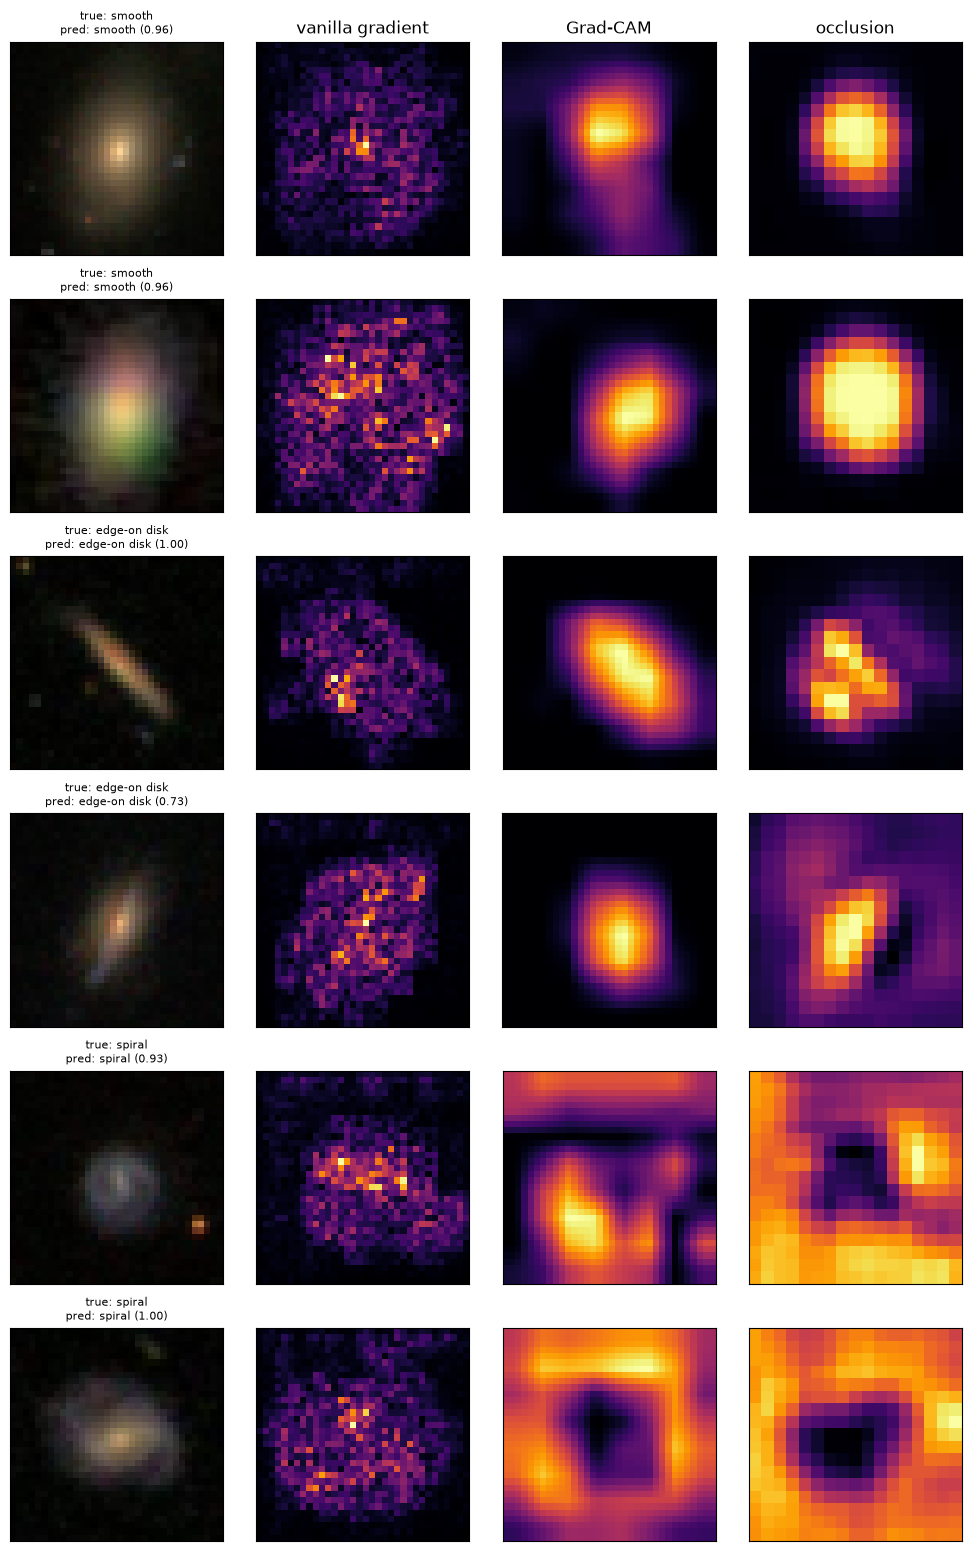

In [13]:
methods = [('vanilla gradient', vanilla_gradient), ('Grad-CAM', grad_cam), ('occlusion', occlusion)]

fig, axes = plt.subplots(len(examples), 4, figsize=(10, 2.6 * len(examples)))
for r, i in enumerate(examples):
    x = Xn[i:i + 1]
    with torch.no_grad():
        prob = F.softmax(model(x), 1)[0]
    c = prob.argmax().item()

    axes[r, 0].imshow(images[i])
    axes[r, 0].set_title(f'true: {class_names[labels[i]]}\npred: {class_names[c]} ({prob[c]:.2f})',
                         fontsize=8)
    for k, (title, method) in enumerate(methods, start=1):
        heat = method(model, x, c).detach().numpy()
        axes[r, k].imshow(heat, cmap='inferno')
        if r == 0:
            axes[r, k].set_title(title)

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
